In [9]:
from helpers import *
mpl.rcParams['font.size'] = 14
Lz = 1.0
kz = 2*np.pi/Lz
cmap = 'PuOr_r'

# Fig. 3a Plot bifurcation of elevator modes at density ratio = 40

In [ ]:
# # Load the data of bifurcation
# data_path = {
#             'B': {'../Data/Ra1e5_Pr7_tau0.01_Rrho40/Base/': [('Lx0.01_upward/',0,None, True),
#                                                 ],
#                 'color': 'gray', 'alpha': 1.0 },
#             'VEM': {'../Data/Ra1e5_Pr7_tau0.01_Rrho40/': [('VEM1/',0,None, True),
#                                 ],
#                 'color': 'r', 'alpha': 0.5, 'scatter_first_point': (True,'o'), 'scatter_stability_change': True},
#             'IEM': {'../Data/Ra1e5_Pr7_tau0.01_Rrho40/': [('IEM1_zoomin_bottom/',0,None, True),
#                                                           ('IEM1/',2,None, True),
#                                                 ],
#                 'color': 'g', 'alpha': 0.5, 'scatter_first_point': True, 'scatter_stability_change': True},
#             }
# bifurcation_data = bifurcation_diagram(data_path, mu='Lx', response='Sh')

# for key, branch_info in bifurcation_data.items():
#     # add Lx for elevator modes, in this modes: Lx is given and continuous parameter is aw0 (amplitude of vertical velocity)
#     if key == 'VEM':
#         Lx_vem = load_file('../Data/Ra1e5_Pr7_tau0.01_Rrho40/VEM1/Lx.txt')
#         bifurcation_data[key]['mu'] = np.array([Lx_vem] * len(bifurcation_data[key]['mu']))
#     if key == 'IEM':
#         Lx_iem = load_file('../Data/Ra1e5_Pr7_tau0.01_Rrho40/IEM1/Lx.txt')
#         bifurcation_data[key]['mu'] = np.array([Lx_iem] * len(bifurcation_data[key]['mu']))
    

# # convert response from Sh=1-Fs/tau to |Fs|/tau
# for key, path in bifurcation_data.items():
#     bifurcation_data[key]['response'] = np.array(bifurcation_data[key]['response']) - 1.0

# with open('supp_Fig2a_data.pkl', 'wb') as f:
#     pickle.dump(bifurcation_data, f)

Loading B data from ../Data/Ra1e5_Pr7_tau0.01_Rrho40/Base/...
    Loading continuation data from ../Data/Ra1e5_Pr7_tau0.01_Rrho40/Base/Lx0.01_upward/...
Loading VEM data from ../Data/Ra1e5_Pr7_tau0.01_Rrho40/...
    Loading continuation data from ../Data/Ra1e5_Pr7_tau0.01_Rrho40/VEM1/...
Loading IEM data from ../Data/Ra1e5_Pr7_tau0.01_Rrho40/...
    Loading continuation data from ../Data/Ra1e5_Pr7_tau0.01_Rrho40/IEM1_zoomin_bottom/...
    Loading continuation data from ../Data/Ra1e5_Pr7_tau0.01_Rrho40/IEM1/...


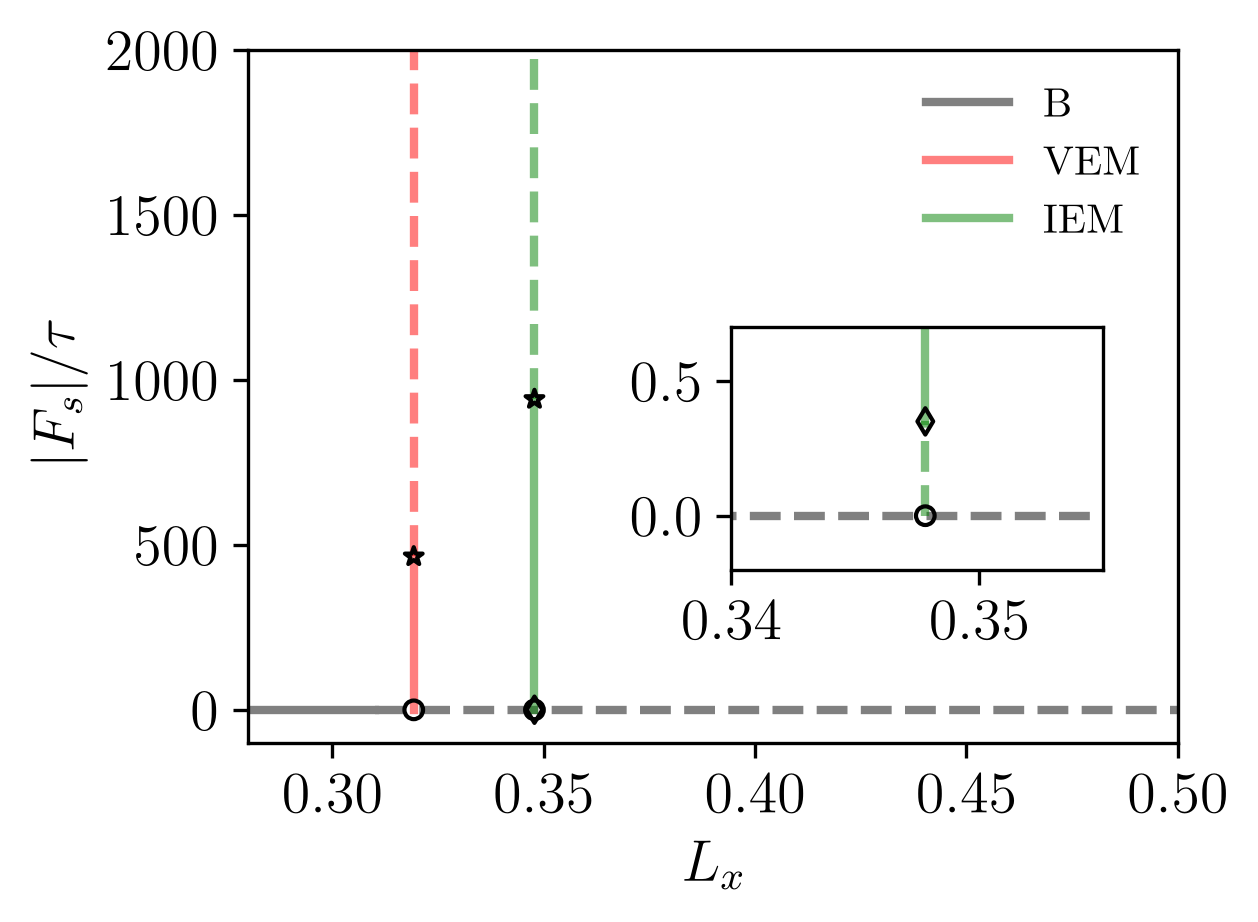

In [11]:
with open('supp_Fig2a_data.pkl', 'rb') as file:
    bifurcation_data = pickle.load(file)

fig, ax = plt.subplots(figsize=(4, 3), dpi=300)
plot_bifurcation_diagram(ax, bifurcation_data, lw=2)
plot_scatter_for_first_point(ax, bifurcation_data)
plot_scatter_for_stability_change(ax, bifurcation_data, marker='*')
ax.set_xlim([0.28,0.5])
ax.set_ylim([-100,2000])
ax.set_xlabel("$L_x$")
ax.set_ylabel(r"$|F_s|/\tau$")
ax.legend(frameon=False, fontsize=10, ncols=1)

ax_zoom = ax.inset_axes([0.52, 0.25, 0.4, 0.35])
plot_bifurcation_diagram(ax_zoom, bifurcation_data, lw=2)
plot_scatter_for_first_point(ax_zoom, bifurcation_data)
plot_scatter_for_stability_change(ax_zoom, bifurcation_data, marker='*')
ax_zoom.set_xlim([0.34,0.355])
ax_zoom.set_ylim([-0.2,0.7])

fig.savefig('supp_Fig2a.png',dpi=300, bbox_inches='tight')
plt.show()


In [12]:
def plot_and_save(sol_path,saving_name=None):
    [x,z,t,s,u,w]=return_fields(sol_path)
    if saving_name != None: 
        fig, ax = plt.subplots(figsize = (3,3))
        X, Z = np.meshgrid(x, z) 
        h1 = ax.pcolormesh(X, Z, s.T, cmap = cmap)
        ax.set_yticks([0, 1])
        ax.set_xlabel('$x$')
        ax.set_ylabel('$z$')
        ax.set_aspect('equal')
        fig.colorbar(h1, ax=ax, orientation='vertical', location='right')
        fig.tight_layout()
        fig.savefig(saving_name, dpi=300, bbox_inches='tight')
        plt.show()
    return x,z,s
def plot_and_save_combination(sol_path,eigenvec_path,saving_name=None,scale=100):
    x,z,s = plot_and_save(sol_path)
    _,_,s_eigenvec = plot_and_save(eigenvec_path)
    fig, ax = plt.subplots(figsize = (3,3))
    X, Z = np.meshgrid(x, z) 
    h1 = ax.pcolormesh(X, Z, (s+scale*s_eigenvec).T, cmap = cmap)
    ax.set_yticks([0, 1])
    ax.set_xlabel('$x$')
    ax.set_ylabel('$z$')
    ax.set_aspect('equal')
    fig.colorbar(h1, ax=ax, orientation='vertical', location='right')
    fig.tight_layout()
    if saving_name != None: fig.savefig(saving_name, dpi=300, bbox_inches='tight')
    plt.show()

## Fig. 3b Plot predicted flow structures due to non-oscillatory instability on VEM

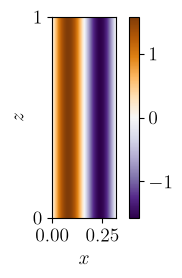

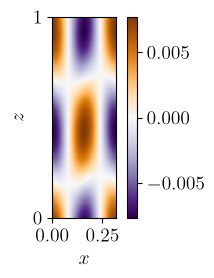

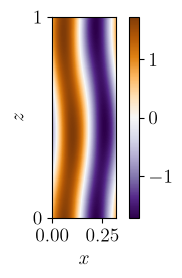

In [13]:
plot_and_save('Samples/Rrho40_Ra1e5_Pr7_tau0.01/Lxc_VEM1_instability/solution.h5',
              'supp_Fig2b_s.png')
plot_and_save('Samples/Rrho40_Ra1e5_Pr7_tau0.01/Lxc_VEM1_instability/first_eigenmode.h5',
              'supp_Fig2b_e1.png')
plot_and_save_combination('Samples/Rrho40_Ra1e5_Pr7_tau0.01/Lxc_VEM1_instability/solution.h5',
                          'Samples/Rrho40_Ra1e5_Pr7_tau0.01/Lxc_VEM1_instability/first_eigenmode.h5',
              'supp_Fig2b_s+100e1.png')

## Fig. 3c Plot predicted flow structures due to oscillatory instability on IEM near base conduction

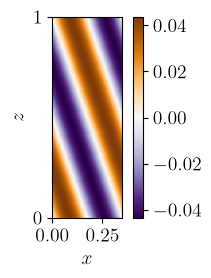

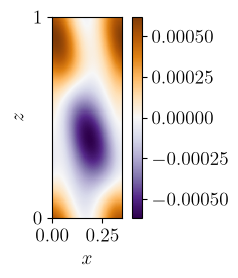

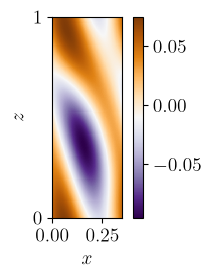

In [14]:
plot_and_save('Samples/Rrho40_Ra1e5_Pr7_tau0.01/Lxc_IEM1_oscillatory_instability/solution.h5',
              'supp_Fig2c_s.png')
plot_and_save('Samples/Rrho40_Ra1e5_Pr7_tau0.01/Lxc_IEM1_oscillatory_instability/first_eigenmode.h5',
              'supp_Fig2c_e1.png')
plot_and_save_combination('Samples/Rrho40_Ra1e5_Pr7_tau0.01/Lxc_IEM1_oscillatory_instability/solution.h5',
                          'Samples/Rrho40_Ra1e5_Pr7_tau0.01/Lxc_IEM1_oscillatory_instability/first_eigenmode.h5')

## Fig. 3d Plot predicted flow structures due to non-oscillatory instability on IEM

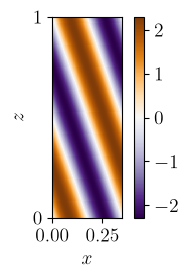

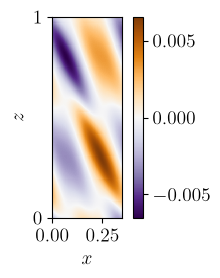

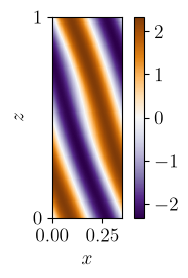

In [15]:
plot_and_save('Samples/Rrho40_Ra1e5_Pr7_tau0.01/Lxc_IEM1_nonoscillatory_instability/solution.h5',
              'supp_Fig2d_s.png')
plot_and_save('Samples/Rrho40_Ra1e5_Pr7_tau0.01/Lxc_IEM1_nonoscillatory_instability/first_eigenmode.h5',
              'supp_Fig2d_e1.png')
plot_and_save_combination('Samples/Rrho40_Ra1e5_Pr7_tau0.01/Lxc_IEM1_nonoscillatory_instability/solution.h5',
                          'Samples/Rrho40_Ra1e5_Pr7_tau0.01/Lxc_IEM1_nonoscillatory_instability/first_eigenmode.h5',
              'supp_Fig2d_s+100e1.png')